In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

print("Environment ready!")


Environment ready!


In [2]:
ticker = "RELIANCE.NS"

data = yf.download(
    ticker,
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True
)

data.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2020-01-01,672.216125,680.008790,670.390471,675.956609,14004468
2020-01-02,683.660278,686.176208,673.284921,673.284921,17710316
2020-01-03,684.484070,686.487896,678.183128,682.636062,20984698
2020-01-06,668.609375,680.365106,667.050830,676.847322,24519177
2020-01-07,678.895630,683.304036,673.952826,676.401934,16683622


In [3]:
data.shape

(1487, 5)

In [4]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1487 entries, 2020-01-01 to 2025-12-31
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   (Close, RELIANCE.NS)   1487 non-null   float64
 1   (High, RELIANCE.NS)    1487 non-null   float64
 2   (Low, RELIANCE.NS)     1487 non-null   float64
 3   (Open, RELIANCE.NS)    1487 non-null   float64
 4   (Volume, RELIANCE.NS)  1487 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 69.7 KB


In [5]:
data.describe()

Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
count,1487.000000,1487.000000,1487.000000,1487.000000,1.487000e+03
mean,1142.191473,1153.908896,1131.306579,1142.822461,1.812071e+07
std,239.408407,239.370851,239.157324,239.119059,1.516411e+07
min,393.662384,423.029534,389.921900,407.978572,0.000000e+00
25%,991.279358,1005.344735,981.222678,993.409028,9.577334e+06
50%,1155.959717,1164.704565,1145.758623,1156.058825,1.331159e+07
75%,1311.350220,1317.794535,1295.388033,1313.161153,2.036149e+07
max,1581.824463,1589.630354,1566.607971,1585.332124,1.426834e+08


In [6]:
data.isnull().sum()

Price   Ticker     
Close   RELIANCE.NS    0
High    RELIANCE.NS    0
Low     RELIANCE.NS    0
Open    RELIANCE.NS    0
Volume  RELIANCE.NS    0
dtype: int64

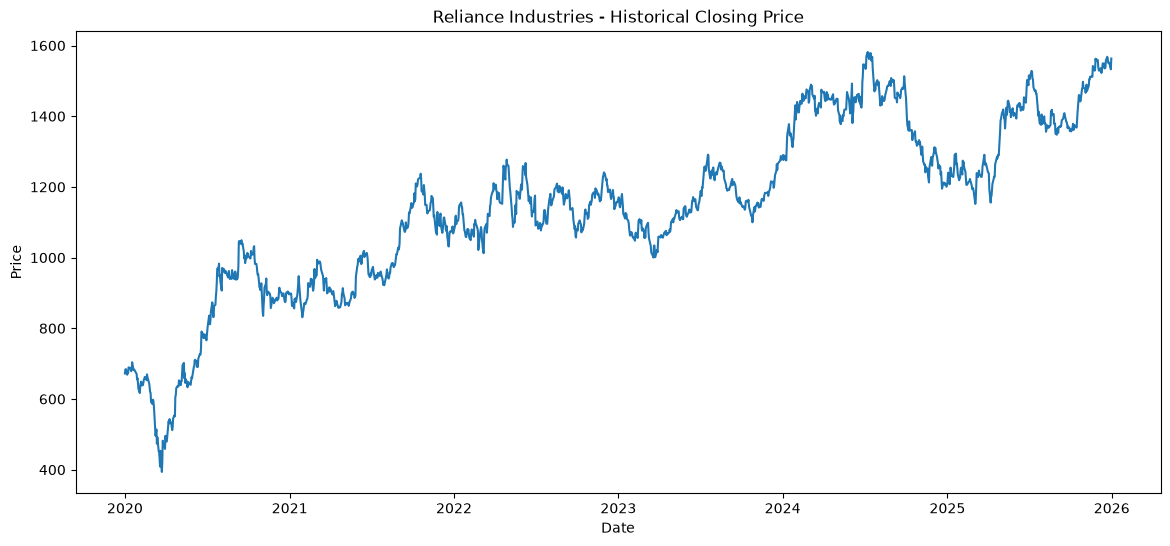

In [7]:
plt.figure(figsize=(14, 6))

plt.plot(data["Close"])

plt.title("Reliance Industries - Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Price")

plt.show()

In [8]:
data.shape

(1487, 5)

In [9]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1487 entries, 2020-01-01 to 2025-12-31
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   (Close, RELIANCE.NS)   1487 non-null   float64
 1   (High, RELIANCE.NS)    1487 non-null   float64
 2   (Low, RELIANCE.NS)     1487 non-null   float64
 3   (Open, RELIANCE.NS)    1487 non-null   float64
 4   (Volume, RELIANCE.NS)  1487 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 69.7 KB


In [10]:
data.isnull().sum()


Price   Ticker     
Close   RELIANCE.NS    0
High    RELIANCE.NS    0
Low     RELIANCE.NS    0
Open    RELIANCE.NS    0
Volume  RELIANCE.NS    0
dtype: int64

In [11]:
data.tail()

Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2025-12-24,1551.028687,1568.448147,1546.449881,1565.461954,8815745
2025-12-26,1552.024048,1553.815812,1547.146696,1547.544758,2311495
2025-12-29,1538.486694,1550.929166,1536.495899,1547.743942,5972105
2025-12-30,1532.713379,1546.449794,1530.722584,1539.880194,8815884
2025-12-31,1563.172607,1569.742208,1533.907890,1533.907890,5771830


In [12]:
stock = data.copy()

In [13]:
stock.isna().sum()

Price   Ticker     
Close   RELIANCE.NS    0
High    RELIANCE.NS    0
Low     RELIANCE.NS    0
Open    RELIANCE.NS    0
Volume  RELIANCE.NS    0
dtype: int64

In [14]:
stock = stock.dropna()

In [15]:
stock.shape

(1487, 5)

In [16]:
stock["Daily_Return"] = stock["Close"].pct_change()

In [17]:
stock[["Close", "Daily_Return"]].tail()

Price,Close,Daily_Return
Ticker,RELIANCE.NS,
Date,,
2025-12-24,1551.028687,-0.007958
2025-12-26,1552.024048,0.000642
2025-12-29,1538.486694,-0.008722
2025-12-30,1532.713379,-0.003753
2025-12-31,1563.172607,0.019873


In [18]:
stock["Volatility_20"] = (
    stock["Daily_Return"]
    .rolling(window=20)
    .std()
)


In [19]:
stock[["Daily_Return", "Volatility_20"]].tail()

Price,Daily_Return,Volatility_20
Ticker,,
Date,,
2025-12-24,-0.007958,0.006427
2025-12-26,0.000642,0.006367
2025-12-29,-0.008722,0.006611
2025-12-30,-0.003753,0.006647
2025-12-31,0.019873,0.007523


In [20]:
stock["MA_20"] = stock["Close"].rolling(20).mean()

In [21]:
stock["MA_50"] = stock["Close"].rolling(50).mean()

In [22]:
stock["MA_200"] = stock["Close"].rolling(200).mean()

In [23]:
stock[["Close", "MA_20", "MA_50", "MA_200"]].tail()

Price,Close,MA_20,MA_50,MA_200
Ticker,RELIANCE.NS,,,
Date,,,,
2025-12-24,1551.028687,1544.150488,1505.576836,1405.612193
2025-12-26,1552.024048,1543.941455,1509.225962,1407.544641
2025-12-29,1538.486694,1542.851495,1512.636194,1409.240857
2025-12-30,1532.713379,1541.542548,1515.453169,1410.708928
2025-12-31,1563.172607,1542.742004,1518.511030,1412.385807


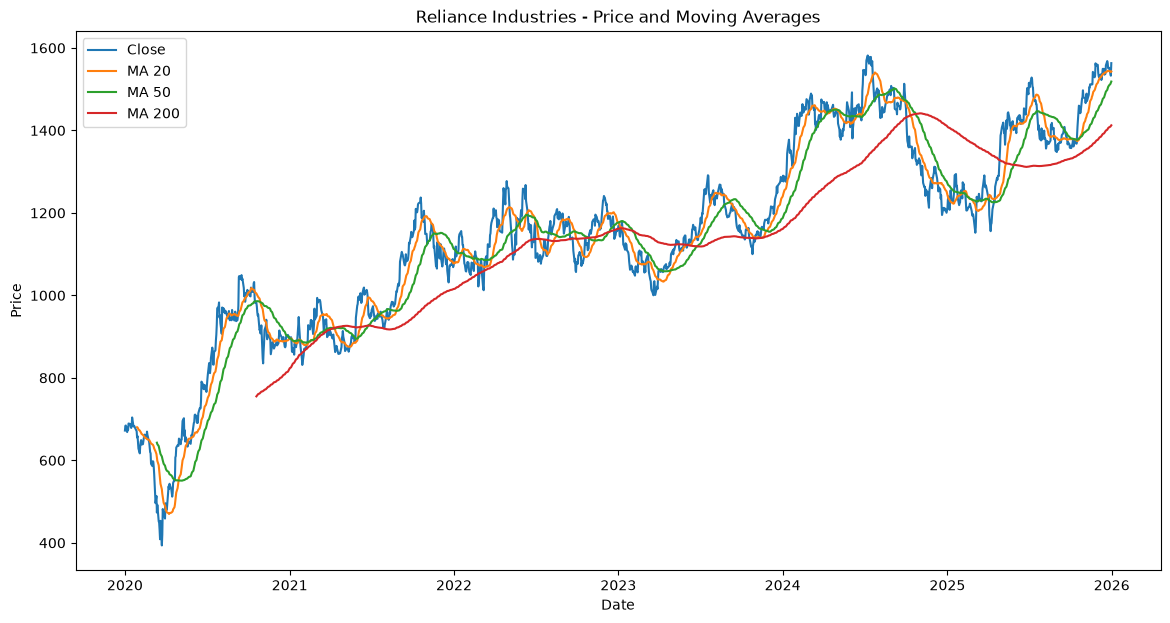

In [24]:
plt.figure(figsize=(14, 7))

plt.plot(stock["Close"], label="Close")
plt.plot(stock["MA_20"], label="MA 20")
plt.plot(stock["MA_50"], label="MA 50")
plt.plot(stock["MA_200"], label="MA 200")

plt.title("Reliance Industries - Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()

plt.show()

In [25]:
delta = stock["Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

rs = avg_gain / avg_loss

stock["RSI_14"] = 100 - (100 / (1 + rs))

In [26]:
stock[["Close", "RSI_14"]].tail(10)

Price,Close,RSI_14
Ticker,RELIANCE.NS,
Date,,
2025-12-17,1537.292236,40.537906
2025-12-18,1537.292236,38.006265
2025-12-19,1557.896851,49.567437
2025-12-22,1568.149536,63.713458
2025-12-23,1563.471069,65.440362
2025-12-24,1551.028687,60.035505
2025-12-26,1552.024048,58.563527
2025-12-29,1538.486694,51.085133


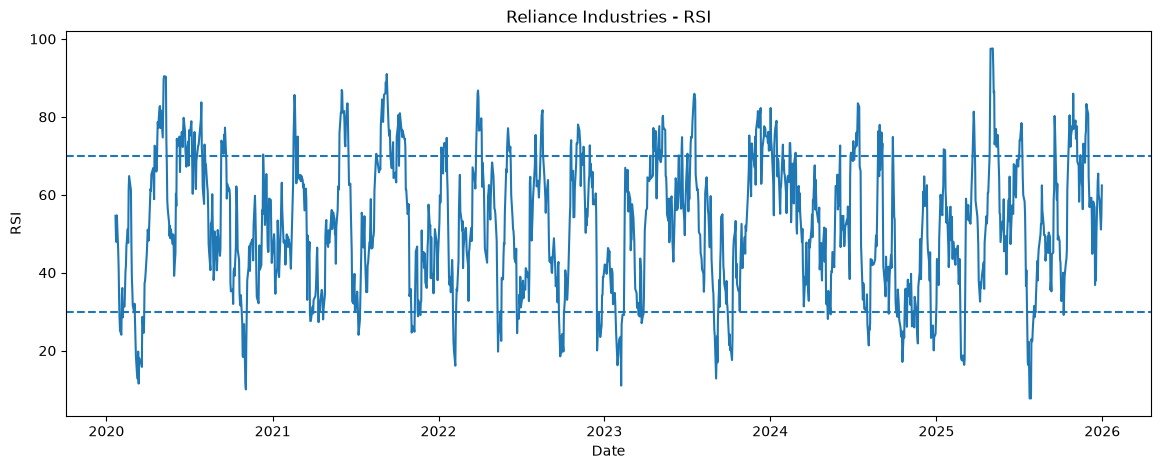

In [27]:
plt.figure(figsize=(14, 5))

plt.plot(stock["RSI_14"])

plt.axhline(70, linestyle="--")
plt.axhline(30, linestyle="--")

plt.title("Reliance Industries - RSI")
plt.xlabel("Date")
plt.ylabel("RSI")

plt.show()

In [28]:
ema_12 = stock["Close"].ewm(span=12, adjust=False).mean()
ema_26 = stock["Close"].ewm(span=26, adjust=False).mean()

stock["MACD"] = ema_12 - ema_26

stock["MACD_Signal"] = (
    stock["MACD"]
    .ewm(span=9, adjust=False)
    .mean()
)

stock["MACD_Hist"] = (
    stock["MACD"] - stock["MACD_Signal"]
)

In [29]:
stock[["MACD", "MACD_Signal", "MACD_Hist"]].tail()

Price,MACD,MACD_Signal,MACD_Hist
Ticker,,,
Date,,,
2025-12-24,13.669117,14.672504,-1.003387
2025-12-26,12.963339,14.330671,-1.367333
2025-12-29,11.182745,13.701086,-2.518341
2025-12-30,9.199705,12.800810,-3.601105
2025-12-31,9.970997,12.234847,-2.263850


In [30]:
rolling_mean = stock["Close"].rolling(20).mean()
rolling_std = stock["Close"].rolling(20).std()

stock["BB_Middle"] = rolling_mean
stock["BB_Upper"] = rolling_mean + (2 * rolling_std)
stock["BB_Lower"] = rolling_mean - (2 * rolling_std)

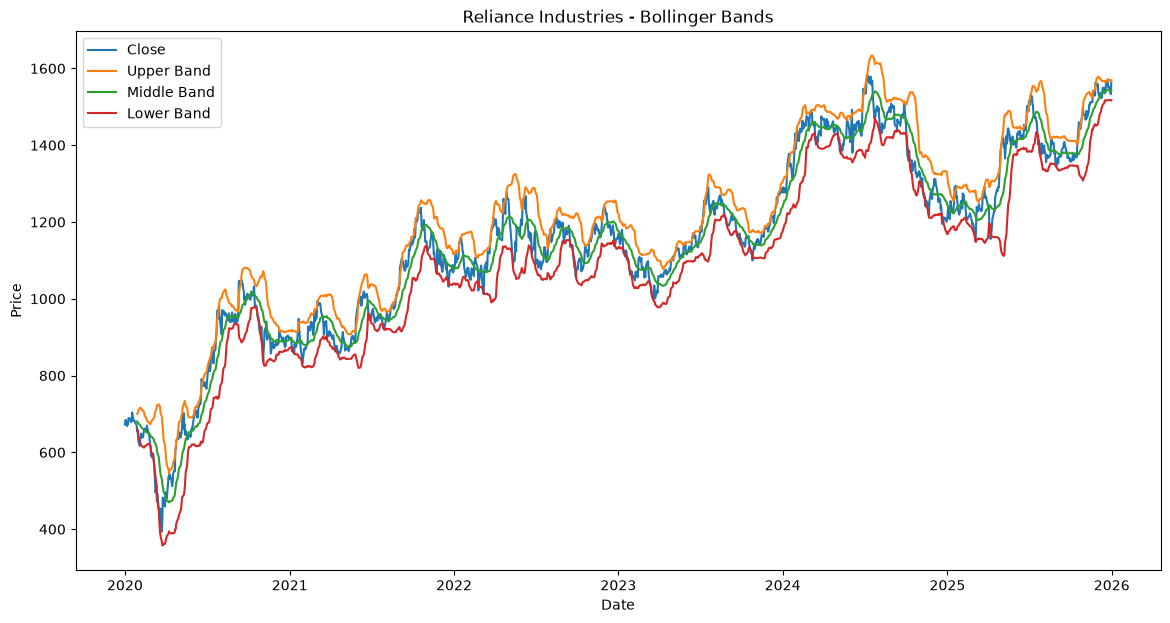

In [31]:
plt.figure(figsize=(14, 7))

plt.plot(stock["Close"], label="Close")
plt.plot(stock["BB_Upper"], label="Upper Band")
plt.plot(stock["BB_Middle"], label="Middle Band")
plt.plot(stock["BB_Lower"], label="Lower Band")

plt.title("Reliance Industries - Bollinger Bands")
plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.show()

In [32]:
stock.columns

MultiIndex([(        'Close', 'RELIANCE.NS'),
            (         'High', 'RELIANCE.NS'),
            (          'Low', 'RELIANCE.NS'),
            (         'Open', 'RELIANCE.NS'),
            (       'Volume', 'RELIANCE.NS'),
            ( 'Daily_Return',            ''),
            ('Volatility_20',            ''),
            (        'MA_20',            ''),
            (        'MA_50',            ''),
            (       'MA_200',            ''),
            (       'RSI_14',            ''),
            (         'MACD',            ''),
            (  'MACD_Signal',            ''),
            (    'MACD_Hist',            ''),
            (    'BB_Middle',            ''),
            (     'BB_Upper',            ''),
            (     'BB_Lower',            '')],
           names=['Price', 'Ticker'])

In [33]:
features_for_corr = [
    "Daily_Return",
    "Volatility_20",
    "MA_20",
    "MA_50",
    "MA_200",
    "RSI_14",
    "MACD",
    "MACD_Hist",
    "Volume_Change"
]

correlation = stock[features_for_corr].corr()

correlation

KeyError: "['Volume_Change'] not in index"

In [ ]:
features_for_corr = [
    "Daily_Return",
    "Volatility_20",
    "MA_20",
    "MA_50",
    "MA_200",
    "RSI_14",
    "MACD",
    "MACD_Hist",
    "Volume_Change"
]

correlation = stock[features_for_corr].corr()

correlation

In [ ]:
stock.columns.tolist()

In [ ]:
stock["Volume_Change"] = stock["Volume"].pct_change()

In [ ]:
stock[["Volume", "Volume_Change"]].tail()

In [ ]:
features_for_corr = [
    "Daily_Return",
    "Volatility_20",
    "MA_20",
    "MA_50",
    "MA_200",
    "RSI_14",
    "MACD",
    "MACD_Hist",
    "Volume_Change"
]

correlation = stock[features_for_corr].corr()

correlation

In [ ]:
stock.columns.tolist()

In [ ]:
features_for_corr = [
    "Daily_Return",
    "Volatility_20",
    "MA_20",
    "MA_50",
    "MA_200",
    "RSI_14",
    "MACD",
    "MACD_Hist",
    "Volume_Change"
]

correlation = stock[features_for_corr].corr()

correlation

In [ ]:
plt.figure(figsize=(12, 8))

plt.imshow(correlation, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(features_for_corr)),
    features_for_corr,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(features_for_corr)),
    features_for_corr
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

In [ ]:
stock.isna().sum()

In [ ]:
stock = stock.dropna().copy()

In [ ]:
stock.shape

In [ ]:
stock["Tomorrow_Return"] = stock["Daily_Return"].shift(-1)

In [ ]:
stock[["Close", "Daily_Return", "Tomorrow_Return"]].tail(10)

In [ ]:
stock["Target"] = (
    stock["Tomorrow_Return"] > 0
).astype(int)

In [ ]:
stock[["Close", "Tomorrow_Return", "Target"]].tail(10)

In [ ]:
stock[["Daily_Return", "Tomorrow_Return", "Target"]].tail()

In [ ]:
stock["Target"].value_counts()

In [ ]:
stock["Target"].value_counts(normalize=True)

In [ ]:
stock["Target"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Target Distribution")
plt.xlabel("Target (0 = Down, 1 = Up)")
plt.ylabel("Number of Days")

plt.show()

In [ ]:
feature_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "Volatility_20",
    "MA_20",
    "MA_50",
    "MA_200",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "BB_Middle",
    "BB_Upper",
    "BB_Lower",
    "Volume_Change"
]

In [ ]:
X = stock[feature_columns]
y = stock["Target"]

In [ ]:
X.shape

In [ ]:
y.shape

In [ ]:
X.head()

In [ ]:
train_test_split(X, y, test_size=0.2)

In [ ]:
stock.index.min(), stock.index.max()

In [ ]:
split_index = int(len(stock) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

In [ ]:
print("Training:", X_train.shape)
print("Testing :", X_test.shape)

In [ ]:
print("Training period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting period:")
print(X_test.index.min(), "to", X_test.index.max())

In [ ]:
train_test_split(X, y, test_size=0.2)

In [ ]:
import pandas as pd

stock = pd.read_csv(
    "../data/processed/reliance_features.csv",
    index_col=0,
    parse_dates=True
)

stock.head()

In [ ]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in project:")
print(os.listdir(".."))

In [ ]:
os.getcwd()

In [ ]:
os.listdir()

In [ ]:
import os

print(os.listdir("data"))
print(os.listdir("data/processed"))

In [ ]:
"stock" in globals()

In [ ]:
data.to_csv("data/raw/reliance_raw.csv")

In [ ]:
import os

print("data folder:")
print(os.listdir("data"))

print("\nprocessed folder:")
print(os.listdir("data/processed"))

In [ ]:
print("stock exists:", "stock" in globals())
print("Rows:", len(stock))
print("Columns:", len(stock.columns))

In [ ]:
print("stock exists:", "stock" in globals())
print("Rows:", len(stock))
print("Columns:", len(stock.columns))

In [ ]:
stock.to_csv("data/processed/reliance_features.csv")

print("Saved successfully!")
print(os.path.exists("data/processed/reliance_features.csv"))

In [ ]:
import os

print(os.path.exists("data/processed/reliance_features.csv"))

In [ ]:
print(os.path.getsize("data/processed/reliance_features.csv"), "bytes")

In [ ]:
import pandas as pd

stock = pd.read_csv(
    "data/processed/reliance_features.csv",
    index_col=0,
    parse_dates=True
)

print(stock.shape)
stock.head()

In [ ]:
stock = pd.read_csv(
    "data/processed/reliance_features.csv",
    parse_dates=["Date"]
)

stock["Date"] = pd.to_datetime(
    stock["Date"],
    format="%Y-%m-%d"
)

In [ ]:
import pandas as pd

stock = pd.read_csv("data/processed/reliance_features.csv")

print(stock.columns.tolist())

In [ ]:
import pandas as pd

stock = pd.read_csv(
    "data/processed/reliance_features.csv"
)

stock["Price"] = pd.to_datetime(stock["Price"])

print(stock.head())
print(stock.dtypes)

In [ ]:
import pandas as pd

stock = pd.read_csv("data/processed/reliance_features.csv")

print(stock.head(10).to_string())

In [ ]:
print(stock.tail(5).to_string())

In [ ]:
print(stock.shape)

In [ ]:
print(stock.head(10).to_string())
print(stock.tail(5).to_string())
print(stock.shape)

In [ ]:
import pandas as pd

# Load the CSV
stock = pd.read_csv("data/processed/reliance_features.csv")

# Remove Yahoo Finance metadata rows
stock = stock.iloc[2:].copy()

# Convert Price column to datetime
stock["Price"] = pd.to_datetime(stock["Price"], format="%Y-%m-%d")

# Reset the index
stock.reset_index(drop=True, inplace=True)

print(stock.head())
print(stock.dtypes)
print(stock.shape)

In [ ]:
stock.rename(columns={"Price": "Date"}, inplace=True)

In [ ]:
stock.set_index("Date", inplace=True)

In [ ]:
import pandas as pd

# Load data
stock = pd.read_csv("data/processed/reliance_features.csv")

# Remove Yahoo Finance metadata rows
stock = stock.iloc[2:].copy()

# Rename Price → Date
stock.rename(columns={"Price": "Date"}, inplace=True)

# Convert Date
stock["Date"] = pd.to_datetime(
    stock["Date"],
    format="%Y-%m-%d"
)

# Reset index
stock.reset_index(drop=True, inplace=True)

# Set Date as index
stock.set_index("Date", inplace=True)

print(stock.head())
print(stock.dtypes)
print(stock.shape)

In [ ]:
# Convert OHLCV columns to numeric
numeric_columns = [
    "Close",
    "High",
    "Low",
    "Open",
    "Volume"
]

stock[numeric_columns] = stock[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

print(stock.dtypes)

In [ ]:
print(stock.isnull().sum())

In [ ]:
print(stock.shape)
print(stock.head())
print(stock.tail())

In [ ]:
stock["Target"] = (stock["Close"].shift(-1) > stock["Close"]).astype(int)

In [ ]:
# Create target variable
# 1 = price goes UP tomorrow
# 0 = price goes DOWN tomorrow

stock["Target"] = (
    stock["Close"].shift(-1) > stock["Close"]
).astype(int)

print(stock[["Close", "Target"]].tail(10))

In [ ]:
# Remove rows with missing values
stock = stock.dropna().copy()

print("Shape after removing NaN:", stock.shape)
print(stock.isnull().sum().sum())

In [ ]:
stock = stock.iloc[:-1].copy()

print(stock.tail())
print(stock.shape)

In [ ]:
features = [
    "Close",
    "High",
    "Low",
    "Open",
    "Volume",
    "Daily_Return",
    "Volatility_20",
    "MA_20",
    "MA_50",
    "MA_200",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "BB_Middle",
    "BB_Upper",
    "BB_Lower"
]

In [ ]:
X = stock[features]
y = stock["Target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

In [ ]:
print(y.value_counts())
print(y.value_counts(normalize=True))

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print(y.value_counts())
print(y.value_counts(normalize=True))

In [ ]:
# Time-based train/test split

split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTrain period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTest period:")
print(X_test.index.min(), "to", X_test.index.max())

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply same scaler to test data
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model training completed!")

In [ ]:
y_pred = model.predict(X_test_scaled)

print("Predictions:")
print(y_pred[:20])

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

In [ ]:
# Time-based train/test split

split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTrain period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTest period:")
print(X_test.index.min(), "to", X_test.index.max())

In [ ]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit scaler ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the training scaler
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Model training completed!")

In [ ]:
# Predict the test data
y_pred = model.predict(X_test_scaled)

print("First 20 predictions:")
print(y_pred[:20])

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

# Detailed performance
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

In [ ]:
stock.to_csv("data/processed/reliance_ml_ready.csv")

print("ML-ready dataset saved successfully!")

In [ ]:
import pandas as pd

stock = pd.read_csv(
    "data/processed/reliance_features.csv",
    index_col=0,
    parse_dates=True
)

print("Dataset shape:", stock.shape)
print(stock.head())

In [ ]:
feature_columns = [
    "Open", "High", "Low", "Close", "Volume",
    "Daily_Return", "Volatility_20",
    "MA_20", "MA_50", "MA_200",
    "RSI_14", "MACD", "MACD_Signal", "MACD_Hist",
    "BB_Middle", "BB_Upper", "BB_Lower",
    "Volume_Change"
]

X = stock[feature_columns]
y = stock["Target"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

In [ ]:
print(stock.columns.tolist())

In [ ]:
stock["Volume_Change"] = stock["Volume"].pct_change()

print("Volume_Change created successfully.")
print(stock[["Volume", "Volume_Change"]].head())

In [ ]:
print(stock["Volume"].dtype)
print(stock["Volume"].head())

In [ ]:
stock["Volume"] = pd.to_numeric(stock["Volume"], errors="coerce")

In [ ]:
print(stock[["Volume", "Volume_Change"]].head())
print(stock["Volume"].dtype)

In [ ]:
print(stock["Volume"].dtype)

In [ ]:
stock["Volume_Change"] = stock["Volume"].pct_change()

In [ ]:
print(stock[["Volume", "Volume_Change"]].head())

In [ ]:
# STEP 9: Create final feature list

feature_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "Volatility_20",
    "MA_20",
    "MA_50",
    "MA_200",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "BB_Middle",
    "BB_Upper",
    "BB_Lower",
    "Volume_Change"
]

print("Number of features:", len(feature_columns))
print("Features:")
for i, feature in enumerate(feature_columns, 1):
    print(f"{i}. {feature}")

In [ ]:
# STEP 10: Create feature matrix X and target y

X = stock[feature_columns].copy()
y = stock["Target"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

In [ ]:
print("stock" in globals())

In [34]:
print("stock" in globals())

True


In [35]:
# STEP 10: Create feature matrix X and target y

X = stock[feature_columns].copy()
y = stock["Target"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

NameError: name 'feature_columns' is not defined

In [36]:
# STEP 9: Define feature columns

feature_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "MA_20",
    "MA_50",
    "EMA_20",
    "RSI",
    "MACD",
    "MACD_Signal",
    "BB_Upper",
    "BB_Lower",
    "Volume_Change"
]

print("Feature columns:")
print(feature_columns)
print("Number of features:", len(feature_columns))

Feature columns:
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'MA_20', 'MA_50', 'EMA_20', 'RSI', 'MACD', 'MACD_Signal', 'BB_Upper', 'BB_Lower', 'Volume_Change']
Number of features: 15


In [37]:
# STEP 10: Create feature matrix X and target y

X = stock[feature_columns].copy()
y = stock["Target"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

KeyError: "['EMA_20' 'RSI' 'Volume_Change'] not in index"

In [ ]:
---------------------------------------------------------------------------
KeyError                                  Traceback (most recent call last)
Cell In[37], line 3
      1 # STEP 10: Create feature matrix X and target y
      2 
----> 3 X = stock[feature_columns].copy()
      4 y = stock["Target"].copy()
      5 
      6 print("X shape:", X.shape)

File F:\IT\AI and ML\Data Science\Projects\StockMarketAI\.venv\Lib\site-packages\pandas\core\frame.py:4384, in DataFrame.__getitem__(self, key)
   4380                 indexer = [indexer]
   4381         else:
   4382             if is_iterator(key):
   4383                 key = list(key)
-> 4384             indexer = self.columns._get_indexer_strict(key, "columns")[1]
   4385 
   4386         # take() does not accept boolean indexers
   4387         if getattr(indexer, "dtype", None) == bool:

File F:\IT\AI and ML\Data Science\Projects\StockMarketAI\.venv\Lib\site-packages\pandas\core\indexes\multi.py:3239, in MultiIndex._get_indexer_strict(self, key, axis_name)
   3236 if len(keyarr) and not isinstance(keyarr[0], tuple):
   3237     indexer = self._get_indexer_level_0(keyarr)
-> 3239     self._raise_if_missing(key, indexer, axis_name)
   3240     return self[indexer], indexer
   3242 return super()._get_indexer_strict(key, axis_name)

File F:\IT\AI and ML\Data Science\Projects\StockMarketAI\.venv\Lib\site-packages\pandas\core\indexes\multi.py:3257, in MultiIndex._raise_if_missing(self, key, indexer, axis_name)
   3255 cmask = check == -1
   3256 if cmask.any():
-> 3257     raise KeyError(f"{keyarr[cmask]} not in index")
   3258 # We get here when levels still contain values which are not
   3259 # actually in Index anymore
   3260 raise KeyError(f"{keyarr} not in index")

KeyError: "['EMA_20' 'RSI' 'Volume_Change'] not in index"

In [38]:
# STEP 9: Create missing technical indicators

# EMA 20
stock["EMA_20"] = stock["Close"].ewm(span=20, adjust=False).mean()

# RSI 14
delta = stock["Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

rs = avg_gain / avg_loss
stock["RSI"] = 100 - (100 / (1 + rs))

# Volume Change
stock["Volume_Change"] = stock["Volume"].pct_change()

print("Missing features created successfully.")
print(stock[["EMA_20", "RSI", "Volume_Change"]].head(20))

Missing features created successfully.
Price           EMA_20        RSI Volume_Change
Ticker                                         
Date                                           
2020-01-01  672.216125        NaN           NaN
2020-01-02  673.306045        NaN      0.264619
2020-01-03  674.370619        NaN      0.184886
2020-01-06  673.821929        NaN      0.168431
2020-01-07  674.305138        NaN     -0.319568
2020-01-08  674.256750        NaN     -0.038104
2020-01-09  675.690916        NaN     -0.066374
2020-01-10  676.973648        NaN     -0.167151
2020-01-13  677.966712        NaN      0.465127
2020-01-14  678.258741        NaN     -0.134876
2020-01-15  678.287583        NaN      0.000084
2020-01-16  678.909521        NaN     -0.187755
2020-01-17  681.300067        NaN      1.293239
2020-01-20  681.399745        NaN      0.104617
2020-01-21  681.555661  54.600567     -0.418583
2020-01-22  681.673401  49.591954     -0.454475
2020-01-23  681.504275  47.885897      0.089600
2

In [39]:
print(stock.columns.tolist())

[('Close', 'RELIANCE.NS'), ('High', 'RELIANCE.NS'), ('Low', 'RELIANCE.NS'), ('Open', 'RELIANCE.NS'), ('Volume', 'RELIANCE.NS'), ('Daily_Return', ''), ('Volatility_20', ''), ('MA_20', ''), ('MA_50', ''), ('MA_200', ''), ('RSI_14', ''), ('MACD', ''), ('MACD_Signal', ''), ('MACD_Hist', ''), ('BB_Middle', ''), ('BB_Upper', ''), ('BB_Lower', ''), ('EMA_20', ''), ('RSI', ''), ('Volume_Change', '')]


In [40]:
# STEP 10: Create feature matrix X and target y

X = stock[feature_columns].copy()
y = stock["Target"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

KeyError: 'Target'

In [41]:
# STEP 9A: Create Target
# 1 = next day's closing price is higher
# 0 = next day's closing price is lower or equal

stock["Target"] = (stock["Close"].shift(-1) > stock["Close"]).astype(int)

print("Target created successfully.")
print(stock[["Close", "Target"]].tail())

Target created successfully.
Price             Close Target
Ticker      RELIANCE.NS       
Date                          
2025-12-24  1551.028687      1
2025-12-26  1552.024048      0
2025-12-29  1538.486694      0
2025-12-30  1532.713379      1
2025-12-31  1563.172607      0


In [42]:
print(stock.columns)

MultiIndex([(        'Close', 'RELIANCE.NS'),
            (         'High', 'RELIANCE.NS'),
            (          'Low', 'RELIANCE.NS'),
            (         'Open', 'RELIANCE.NS'),
            (       'Volume', 'RELIANCE.NS'),
            ( 'Daily_Return',            ''),
            ('Volatility_20',            ''),
            (        'MA_20',            ''),
            (        'MA_50',            ''),
            (       'MA_200',            ''),
            (       'RSI_14',            ''),
            (         'MACD',            ''),
            (  'MACD_Signal',            ''),
            (    'MACD_Hist',            ''),
            (    'BB_Middle',            ''),
            (     'BB_Upper',            ''),
            (     'BB_Lower',            ''),
            (       'EMA_20',            ''),
            (          'RSI',            ''),
            ('Volume_Change',            ''),
            (       'Target',            '')],
           names=['Price', 'Ticke

In [43]:
MultiIndex([
    ('Close', 'RELIANCE.NS'),
    ('Volume', 'RELIANCE.NS'),
    ...
])

NameError: name 'MultiIndex' is not defined

In [44]:
print(stock.columns)


MultiIndex([(        'Close', 'RELIANCE.NS'),
            (         'High', 'RELIANCE.NS'),
            (          'Low', 'RELIANCE.NS'),
            (         'Open', 'RELIANCE.NS'),
            (       'Volume', 'RELIANCE.NS'),
            ( 'Daily_Return',            ''),
            ('Volatility_20',            ''),
            (        'MA_20',            ''),
            (        'MA_50',            ''),
            (       'MA_200',            ''),
            (       'RSI_14',            ''),
            (         'MACD',            ''),
            (  'MACD_Signal',            ''),
            (    'MACD_Hist',            ''),
            (    'BB_Middle',            ''),
            (     'BB_Upper',            ''),
            (     'BB_Lower',            ''),
            (       'EMA_20',            ''),
            (          'RSI',            ''),
            ('Volume_Change',            ''),
            (       'Target',            '')],
           names=['Price', 'Ticke